# A3.2 — Clustering: K-Means y Hierarchical Clustering

**Objetivo:** aplicar dos métodos de aprendizaje no supervisado, visualizar los grupos encontrados y explicar qué muestran los resultados.

Este tutorial sigue los pasos de los materiales **C3.3 K-Means Clustering** y **C3.4 Hierarchical Clustering**. Se trabajará primero con un conjunto sintético y después con el conjunto NCI60 de la librería `ISLP`.

> **Cómo usar este cuaderno:** ejecútalo en orden, de arriba hacia abajo. Cada sección incluye una explicación, el código y una guía para interpretar la salida. Los resultados numéricos y las gráficas se generan al ejecutar las celdas; no deben inventarse ni copiarse de otra ejecución.

## 1. Preparar el entorno

Instalamos o importamos las librerías necesarias. `scikit-learn` contiene los algoritmos K-Means y PCA; `SciPy` permite realizar el clustering jerárquico y dibujar dendrogramas; `ISLP` proporciona el conjunto NCI60.

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "axes.titlesize": 12, "axes.labelsize": 10, "legend.fontsize": 9})
RANDOM_STATE = 42

# Parte I. K-Means con datos sintéticos

## 2. Crear y visualizar el conjunto de datos

Se generarán **1,000 observaciones**, con **3 centros**, **2 variables** y desviación estándar de **1.5**, tal como indica el material C3.3. No usaremos etiquetas verdaderas en la gráfica inicial: la idea es observar los puntos sin conocer sus grupos.

Dimensiones del conjunto: (1000, 2)


,Variable 1,Variable 2
0,-6.454695,-7.268467
1,-5.766484,-6.431171
2,5.477369,2.087178
3,-3.198239,7.739520
4,-2.898585,6.759572


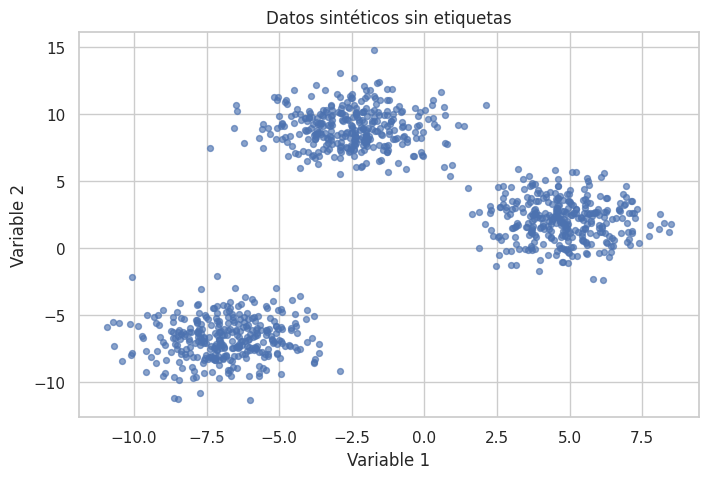

In [3]:
X_sintetico, etiquetas_reales = make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    cluster_std=1.5,
    random_state=RANDOM_STATE
)

datos_sinteticos = pd.DataFrame(X_sintetico, columns=["Variable 1", "Variable 2"])
print("Dimensiones del conjunto:", datos_sinteticos.shape)
display(datos_sinteticos.head())

plt.figure(figsize=(8, 5))
plt.scatter(X_sintetico[:, 0], X_sintetico[:, 1], s=18, alpha=0.65)
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("Datos sintéticos sin etiquetas")
plt.show()

**Interpretación:** cada punto representa una observación y los ejes son las dos variables creadas. La gráfica permite intuir zonas con concentraciones de puntos, pero todavía no se ha aplicado ningún algoritmo de clustering.

## 3. Inicializar grupos y calcular centroides

Para comprender el mecanismo de K-Means, asignaremos inicialmente cada observación a uno de tres grupos al azar. Después calcularemos el centroide de cada grupo, que es el promedio de cada variable para las observaciones que lo integran.

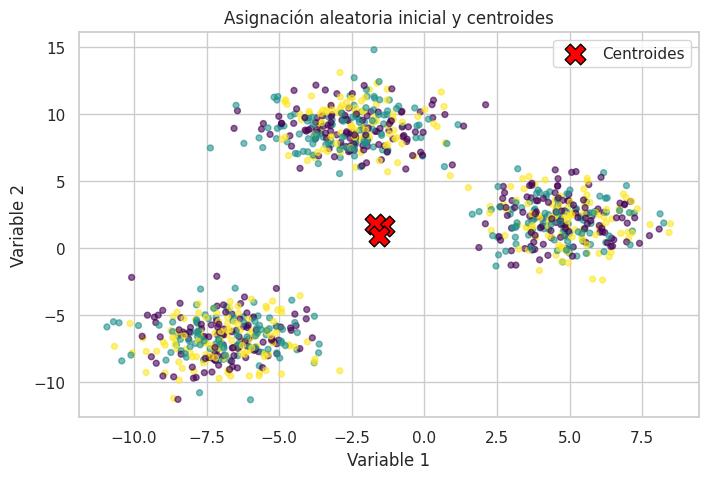

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
K = 3
etiquetas = rng.integers(0, K, size=len(X_sintetico))

def calcular_centroides(X, labels, k):
    centroides = []
    for grupo in range(k):
        puntos = X[labels == grupo]
        if len(puntos) == 0:
            centroides.append(np.full(X.shape[1], np.nan))
        else:
            centroides.append(puntos.mean(axis=0))
    return np.array(centroides)

centroides = calcular_centroides(X_sintetico, etiquetas, K)

plt.figure(figsize=(8, 5))
plt.scatter(X_sintetico[:, 0], X_sintetico[:, 1], c=etiquetas, cmap="viridis", s=18, alpha=0.6)
plt.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=220, c="red", edgecolor="black", label="Centroides")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("Asignación aleatoria inicial y centroides")
plt.legend()
plt.show()

**Interpretación:** al inicio, los colores no necesariamente representan grupos naturales. Los centroides son los promedios de las observaciones asignadas a cada grupo y cambiarán conforme se actualicen las asignaciones.

## 4. Actualizar los grupos de forma iterativa

K-Means repite dos operaciones: (1) asigna cada punto al centroide más cercano usando distancia euclidiana y (2) recalcula los centroides. El proceso termina cuando las asignaciones dejan de cambiar o se alcanza el máximo de iteraciones.

Iteraciones realizadas: 4
Centroides finales:


,Variable 1,Variable 2
0,4.784705,2.086796
1,-2.521398,8.988057
2,-6.860030,-6.737737


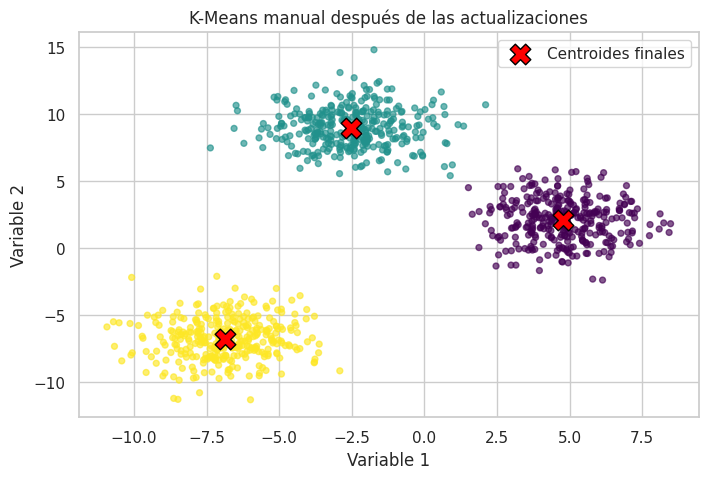

In [5]:
def ejecutar_kmeans_manual(X, labels_iniciales, k, max_iter=100):
    labels = labels_iniciales.copy()
    historial = []
    for iteracion in range(max_iter):
        centroides = calcular_centroides(X, labels, k)

        # Si algún grupo quedó vacío, inicializamos su centroide con un punto existente.
        for j in range(k):
            if np.isnan(centroides[j]).any():
                centroides[j] = X[rng.integers(0, len(X))]

        distancias = np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2)
        nuevas_labels = np.argmin(distancias, axis=1)
        nuevos_centroides = calcular_centroides(X, nuevas_labels, k)
        historial.append((nuevas_labels.copy(), nuevos_centroides.copy()))

        if np.array_equal(nuevas_labels, labels):
            labels = nuevas_labels
            break
        labels = nuevas_labels
    return labels, calcular_centroides(X, labels, k), iteracion + 1

etiquetas_finales, centroides_finales, iteraciones = ejecutar_kmeans_manual(
    X_sintetico, etiquetas, K
)

print(f"Iteraciones realizadas: {iteraciones}")
print("Centroides finales:")
display(pd.DataFrame(centroides_finales, columns=["Variable 1", "Variable 2"]))

plt.figure(figsize=(8, 5))
plt.scatter(X_sintetico[:, 0], X_sintetico[:, 1], c=etiquetas_finales, cmap="viridis", s=18, alpha=0.65)
plt.scatter(centroides_finales[:, 0], centroides_finales[:, 1], marker="X", s=220, c="red", edgecolor="black", label="Centroides finales")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("K-Means manual después de las actualizaciones")
plt.legend()
plt.show()

**Interpretación:** compara esta gráfica con la asignación inicial. K-Means mueve los centroides y reasigna puntos para reducir la variación dentro de los grupos. Como las asignaciones iniciales son aleatorias, diferentes inicios pueden producir resultados distintos.

## 5. K-Means con scikit-learn

Ahora utilizaremos la implementación de `scikit-learn`. Se fija `n_init=20`, dentro del intervalo de 10 a 50 recomendado en el material. El algoritmo prueba distintas inicializaciones y conserva la mejor solución según su criterio interno.

Inercia (suma de distancias cuadradas a los centroides): 4387.88
Silhouette score: 0.765


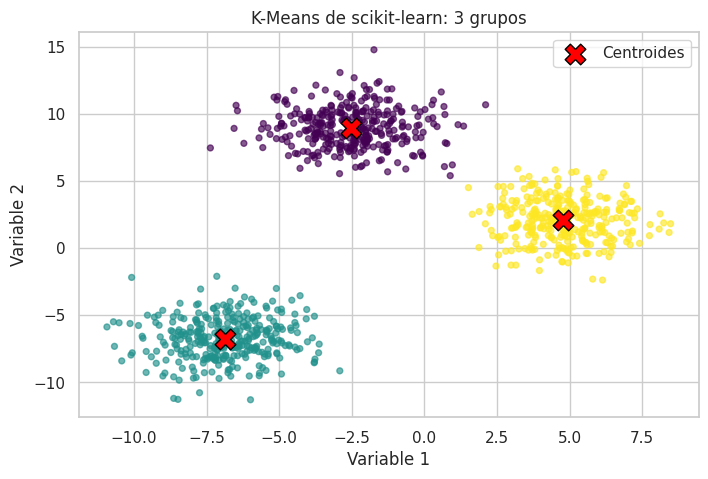

In [6]:
modelo_sintetico = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE)
labels_sklearn = modelo_sintetico.fit_predict(X_sintetico)

print("Inercia (suma de distancias cuadradas a los centroides):", round(modelo_sintetico.inertia_, 2))
print("Silhouette score:", round(silhouette_score(X_sintetico, labels_sklearn), 3))

plt.figure(figsize=(8, 5))
plt.scatter(X_sintetico[:, 0], X_sintetico[:, 1], c=labels_sklearn, cmap="viridis", s=18, alpha=0.65)
plt.scatter(modelo_sintetico.cluster_centers_[:, 0], modelo_sintetico.cluster_centers_[:, 1],
            marker="X", s=220, c="red", edgecolor="black", label="Centroides")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("K-Means de scikit-learn: 3 grupos")
plt.legend()
plt.show()

**Interpretación:** la inercia mide la suma de distancias cuadradas de los puntos a sus centroides; para un mismo conjunto de datos suele disminuir al aumentar el número de grupos, por lo que no debe interpretarse sola. El *silhouette score* resume qué tan separados están los grupos: valores cercanos a 1 indican grupos bien separados, alrededor de 0 indican solapamiento y valores negativos pueden indicar asignaciones poco adecuadas.

# Parte II. K-Means con el conjunto NCI60

## 6. Cargar y revisar NCI60

El material C3.3 indica cargar `NCI60` desde `ISLP`, revisar sus dimensiones y contar las etiquetas de clase. NCI60 contiene perfiles de expresión génica de líneas celulares; las etiquetas de clase se usarán después para comparar los grupos obtenidos, no para entrenar el algoritmo de clustering.

In [7]:
from ISLP import load_data

NCI60 = load_data("NCI60")
print("Tipo de objeto:", type(NCI60))
print("Atributos disponibles:", [a for a in dir(NCI60) if not a.startswith("_")][:30])

Tipo de objeto: <class 'dict'>
Atributos disponibles: ['clear', 'copy', 'fromkeys', 'get', 'items', 'keys', 'pop', 'popitem', 'setdefault', 'update', 'values']


In [9]:
# Accedemos a los datos usando las claves del diccionario retornado por ISLP
X_nci = NCI60.get("data")
y_nci = NCI60.get("labels")

if isinstance(X_nci, pd.DataFrame):
    X_nci_df = X_nci.copy()
else:
    X_nci_df = pd.DataFrame(np.asarray(X_nci))

y_nci = pd.Series(np.asarray(y_nci).ravel(), name="Clase")

print("Dimensiones de la matriz de expresión:", X_nci_df.shape)
print("\nCantidad de muestras por clase:")
display(y_nci.value_counts().sort_index().to_frame("Cantidad"))
print("\nPrimeras filas de los datos:")
display(X_nci_df.iloc[:5, :5])

Dimensiones de la matriz de expresión: (64, 6830)

Cantidad de muestras por clase:


,Cantidad
Clase,
BREAST,7
CNS,5
COLON,7
K562A-repro,1
K562B-repro,1
LEUKEMIA,6
MCF7A-repro,1
MCF7D-repro,1
MELANOMA,8



Primeras filas de los datos:


,0,1,2,3,4
0,0.300000,1.180000,0.550000,1.140000,-0.265000
1,0.679961,1.289961,0.169961,0.379961,0.464961
2,0.940000,-0.040000,-0.170000,-0.040000,-0.605000
3,0.280000,-0.310000,0.680000,-0.810000,0.625000
4,0.485000,-0.465000,0.395000,0.905000,0.200000


**Interpretación:** las filas representan muestras y las columnas representan genes/variables. La tabla de clases describe las categorías conocidas de las muestras. Como el clustering es no supervisado, estas etiquetas se reservan para evaluar e interpretar los grupos después de entrenar.

## 7. Ejecutar K-Means con distintos números de grupos

El documento propone probar entre **3 y 5 clusters** y usar múltiples inicializaciones (`n_init` entre 10 y 50). Se compararán la inercia y el coeficiente silhouette para orientar la elección, recordando que ninguna métrica sustituye la interpretación del problema.

In [10]:
# Estandarizar las variables para que los genes estén en una escala comparable.
escalador = StandardScaler()
X_nci_std = escalador.fit_transform(X_nci_df)

resultados_k = []
modelos_k = {}
for k in range(3, 6):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = modelo.fit_predict(X_nci_std)
    modelos_k[k] = (modelo, labels)
    resultados_k.append({
        "k": k,
        "Inercia": modelo.inertia_,
        "Silhouette": silhouette_score(X_nci_std, labels)
    })

tabla_k = pd.DataFrame(resultados_k)
display(tabla_k)

,k,Inercia,Silhouette
0,3,372673.427236,0.077619
1,4,350737.487472,0.085167
2,5,336620.615731,0.081064


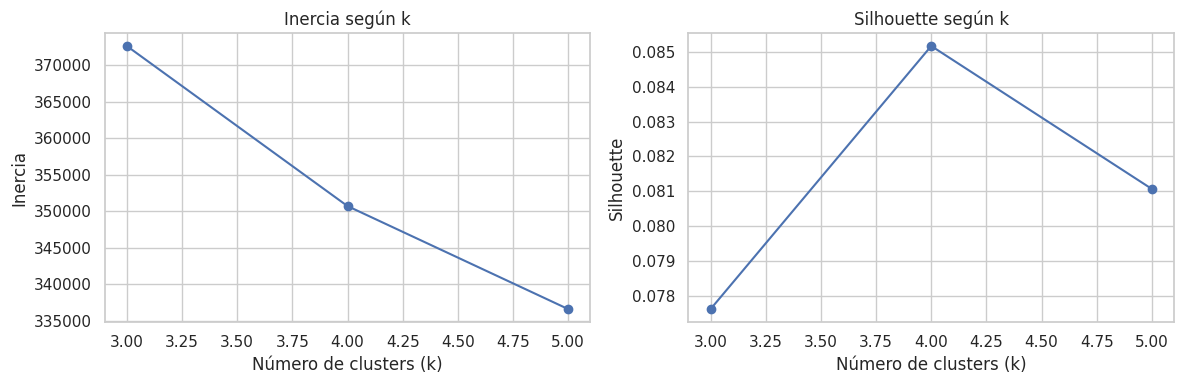

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tabla_k["k"], tabla_k["Inercia"], marker="o")
axes[0].set_title("Inercia según k")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")

axes[1].plot(tabla_k["k"], tabla_k["Silhouette"], marker="o")
axes[1].set_title("Silhouette según k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Interpretación:** la inercia normalmente disminuye cuando aumenta `k`; busca un posible “codo”, donde la mejora deja de ser tan marcada. El silhouette ayuda a comparar separación y cohesión. Elige un valor justificándolo con la tabla y las gráficas; no existe garantía de que una sola métrica determine el número correcto de grupos.

## 8. Visualizar pares de variables originales

El material sugiere graficar algunos pares de variables para visualizar los clusters. Debido a que NCI60 tiene miles de genes, aquí se muestran las primeras tres variables como ejemplo. Estas gráficas son proyecciones parciales y no resumen toda la información del conjunto.

k elegido automáticamente como referencia por silhouette: 4


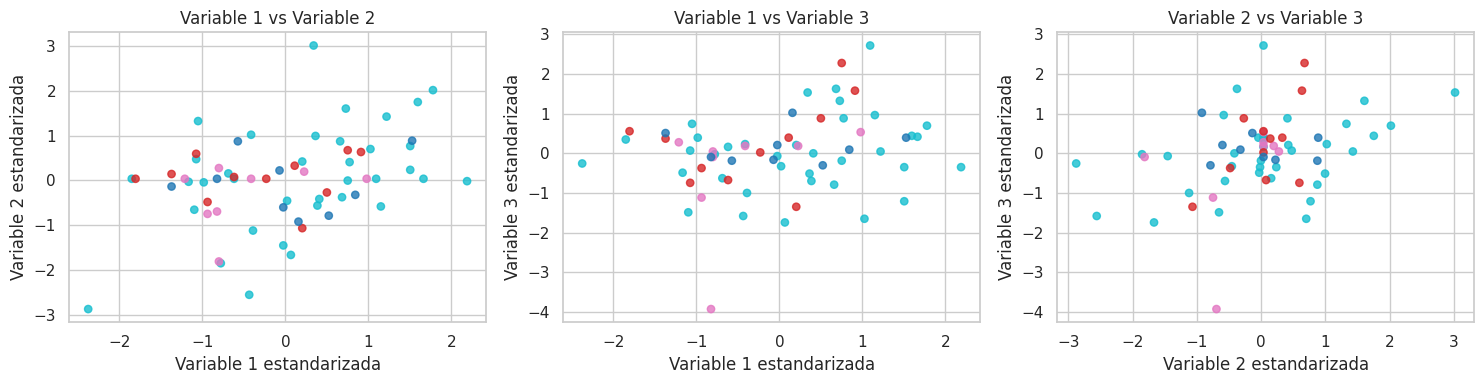

In [12]:
k_elegido = int(tabla_k.loc[tabla_k["Silhouette"].idxmax(), "k"])
modelo_nci, labels_nci = modelos_k[k_elegido]
print("k elegido automáticamente como referencia por silhouette:", k_elegido)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pares = [(0, 1), (0, 2), (1, 2)]
for ax, (i, j) in zip(axes, pares):
    ax.scatter(X_nci_std[:, i], X_nci_std[:, j], c=labels_nci, cmap="tab10", s=28, alpha=0.8)
    ax.set_xlabel(f"Variable {i+1} estandarizada")
    ax.set_ylabel(f"Variable {j+1} estandarizada")
    ax.set_title(f"Variable {i+1} vs Variable {j+1}")
plt.tight_layout()
plt.show()

## 9. Reducir dimensiones con PCA

NCI60 tiene muchas variables. PCA transforma los datos en componentes principales que resumen la variación de los datos. Primero observaremos la varianza explicada y después graficaremos PC1–PC2, PC1–PC3 y PC2–PC3. PCA ayuda a visualizar, pero los componentes no son genes individuales.

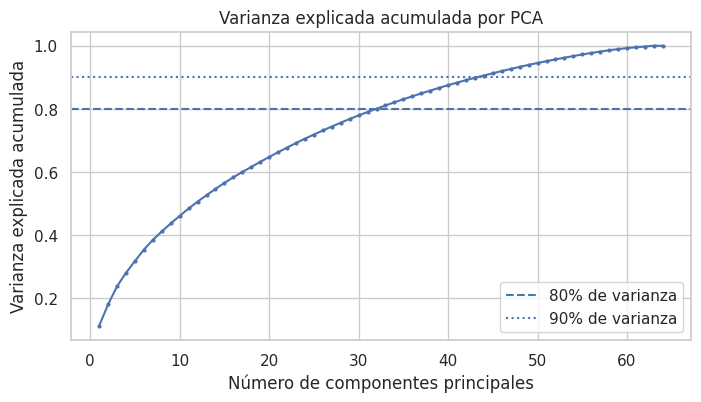

Componentes necesarios para alcanzar al menos 80% de varianza: 32


In [13]:
pca_completo = PCA()
X_nci_pca_completo = pca_completo.fit_transform(X_nci_std)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(varianza_acumulada) + 1), varianza_acumulada, marker=".", markersize=4)
plt.axhline(0.80, linestyle="--", label="80% de varianza")
plt.axhline(0.90, linestyle=":", label="90% de varianza")
plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada por PCA")
plt.legend()
plt.show()

n_componentes_80 = int(np.argmax(varianza_acumulada >= 0.80) + 1)
print("Componentes necesarios para alcanzar al menos 80% de varianza:", n_componentes_80)

**Interpretación:** la curva muestra cuánta variación total queda resumida al conservar cierto número de componentes. El 80% es una referencia visual y no una regla universal; justifica la selección observando el gráfico y considerando el objetivo del análisis.

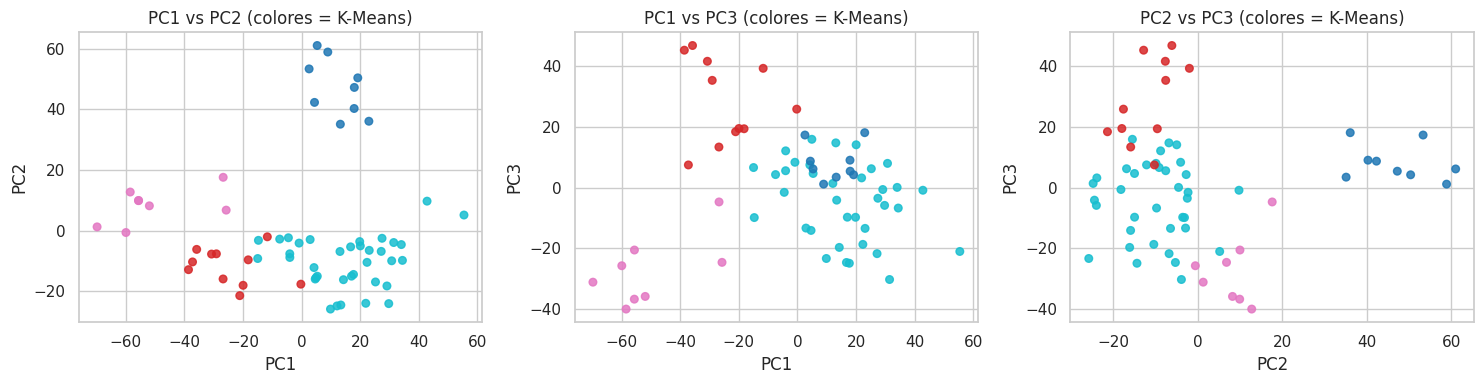

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pares_pca = [(0, 1), (0, 2), (1, 2)]
for ax, (i, j) in zip(axes, pares_pca):
    ax.scatter(X_nci_pca_completo[:, i], X_nci_pca_completo[:, j], c=labels_nci, cmap="tab10", s=30, alpha=0.85)
    ax.set_xlabel(f"PC{i+1}")
    ax.set_ylabel(f"PC{j+1}")
    ax.set_title(f"PC{i+1} vs PC{j+1} (colores = K-Means)")
plt.tight_layout()
plt.show()

**Interpretación:** los colores muestran los grupos de K-Means en las proyecciones de los componentes principales. Si se observan zonas separadas, eso sugiere diferencias en esos componentes; si hay solapamiento, no significa necesariamente que los grupos sean idénticos, ya que la gráfica solo muestra dos dimensiones a la vez.

## 10. Aplicar K-Means a los componentes principales

Usaremos el número de componentes que alcanza al menos 80% de varianza explicada como punto de partida. Se vuelve a ajustar K-Means y se comparan los grupos en las proyecciones PCA. También se calcula silhouette para describir la separación en el espacio reducido.

In [15]:
n_componentes = max(2, n_componentes_80)
pca = PCA(n_components=n_componentes)
X_nci_pca = pca.fit_transform(X_nci_std)

resultados_pca = []
modelos_pca = {}
for k in range(3, 6):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = modelo.fit_predict(X_nci_pca)
    modelos_pca[k] = (modelo, labels)
    resultados_pca.append({
        "k": k,
        "Inercia": modelo.inertia_,
        "Silhouette": silhouette_score(X_nci_pca, labels)
    })

tabla_pca_k = pd.DataFrame(resultados_pca)
display(tabla_pca_k)

,k,Inercia,Silhouette
0,3,285273.903318,0.107354
1,4,264472.226252,0.120989
2,5,247934.227605,0.131887


Componentes usados: 32
k de referencia seleccionado en PCA: 5


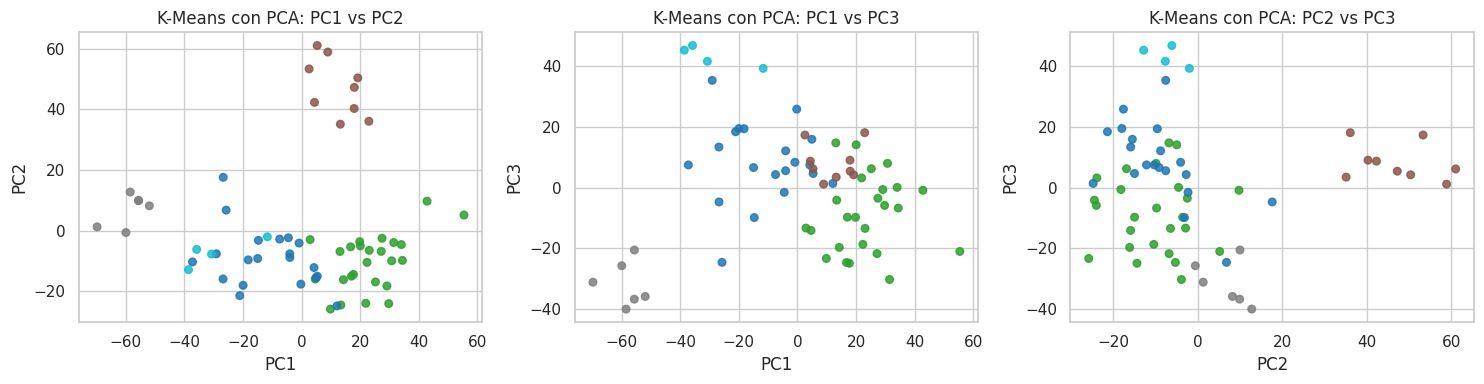

In [16]:
k_pca = int(tabla_pca_k.loc[tabla_pca_k["Silhouette"].idxmax(), "k"])
modelo_pca, labels_pca = modelos_pca[k_pca]
print(f"Componentes usados: {n_componentes}")
print(f"k de referencia seleccionado en PCA: {k_pca}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(X_nci_pca[:, i], X_nci_pca[:, j], c=labels_pca, cmap="tab10", s=30, alpha=0.85)
    ax.set_xlabel(f"PC{i+1}")
    ax.set_ylabel(f"PC{j+1}")
    ax.set_title(f"K-Means con PCA: PC{i+1} vs PC{j+1}")
plt.tight_layout()
plt.show()

**Interpretación:** compara estos resultados con K-Means aplicado a las variables estandarizadas originales. PCA reduce la dimensionalidad y puede facilitar la visualización; el agrupamiento puede cambiar porque el algoritmo ahora trabaja con una representación transformada de los datos.

## 11. Comparar las clases conocidas con los clusters

Las etiquetas de clase no se usaron para formar los clusters. Esta tabla permite observar cuántas muestras de cada clase conocida quedaron en cada grupo. Una clase concentrada en un cluster sugiere correspondencia; una clase repartida entre varios clusters indica que el agrupamiento no coincide exactamente con esas clases.

Cluster K-Means PCA,0,1,2,3,4
Clase real,,,,,
BREAST,0,3,2,0,2
CNS,0,5,0,0,0
COLON,7,0,0,0,0
K562A-repro,0,0,0,1,0
K562B-repro,0,0,0,1,0
LEUKEMIA,2,0,0,4,0
MCF7A-repro,0,0,0,0,1
MCF7D-repro,0,0,0,0,1
MELANOMA,0,1,7,0,0


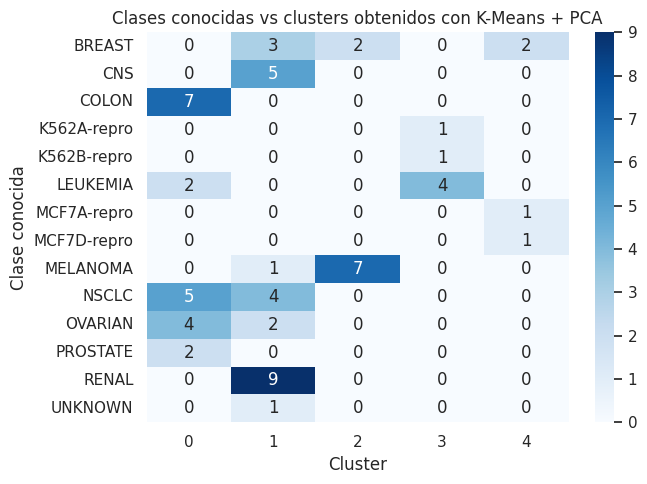

In [17]:
tabla_clases_clusters = pd.crosstab(
    pd.Series(y_nci, name="Clase real"),
    pd.Series(labels_pca, name="Cluster K-Means PCA")
)
display(tabla_clases_clusters)

plt.figure(figsize=(max(7, tabla_clases_clusters.shape[1] * 1.2), max(5, tabla_clases_clusters.shape[0] * 0.35)))
sns.heatmap(tabla_clases_clusters, annot=True, fmt="d", cmap="Blues")
plt.title("Clases conocidas vs clusters obtenidos con K-Means + PCA")
plt.xlabel("Cluster")
plt.ylabel("Clase conocida")
plt.tight_layout()
plt.show()

## 12. Heatmap de genes que más diferencian dos clusters

Siguiendo C3.3, seleccionaremos dos clusters, calcularemos la expresión promedio por gen para cada uno, mediremos la diferencia absoluta y elegiremos hasta 50 genes con mayor diferencia. Después estandarizaremos esos genes y graficaremos un heatmap agrupado por cluster.

Esta visualización identifica genes que diferencian a los dos grupos elegidos; por sí sola no demuestra causalidad ni significancia estadística.

In [18]:
clusters_disponibles = np.unique(labels_pca)
cluster_a, cluster_b = int(clusters_disponibles[0]), int(clusters_disponibles[1])

X_nci_df = X_nci_df.copy()
promedio_a = X_nci_df.iloc[labels_pca == cluster_a].mean(axis=0)
promedio_b = X_nci_df.iloc[labels_pca == cluster_b].mean(axis=0)
diferencia = (promedio_a - promedio_b).abs()
genes_seleccionados = diferencia.nlargest(min(50, X_nci_df.shape[1])).index

print(f"Clusters comparados: {cluster_a} y {cluster_b}")
print("Cantidad de genes seleccionados:", len(genes_seleccionados))
display(diferencia.loc[genes_seleccionados].head(10).to_frame("Diferencia absoluta de promedios"))

Clusters comparados: 0 y 1
Cantidad de genes seleccionados: 50


,Diferencia absoluta de promedios
5803,3.397749
5941,3.364249
255,3.237851
5804,3.123147
5827,3.072148
256,3.066801
6148,2.933049
5942,2.918998
5844,2.907599
6149,2.855749


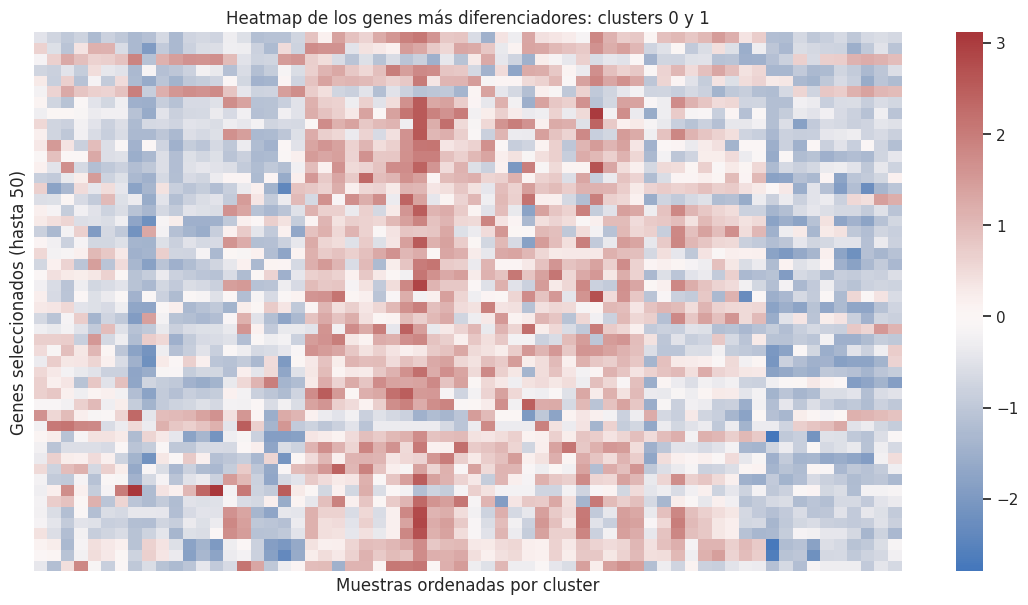

In [19]:
X_heat = X_nci_df.loc[:, genes_seleccionados].copy()
X_heat_std = (X_heat - X_heat.mean(axis=0)) / X_heat.std(axis=0).replace(0, 1)
orden = np.argsort(labels_pca)

plt.figure(figsize=(14, 7))
sns.heatmap(
    X_heat_std.iloc[orden].T,
    cmap="vlag",
    center=0,
    xticklabels=False,
    yticklabels=False
)
plt.title(f"Heatmap de los genes más diferenciadores: clusters {cluster_a} y {cluster_b}")
plt.xlabel("Muestras ordenadas por cluster")
plt.ylabel("Genes seleccionados (hasta 50)")
plt.show()

**Interpretación:** en el heatmap, los colores representan expresión relativa estandarizada por gen: valores positivos están por encima del promedio del gen y valores negativos por debajo. Los patrones de color distintos entre los dos bloques de muestras indican qué genes muestran mayores diferencias relativas entre esos clusters.

# Parte III. Hierarchical Clustering con NCI60

## 13. PCA para preparar la visualización y el clustering jerárquico

El material C3.4 pide usar NCI60, aplicar PCA, graficar la varianza explicada y PC1 frente a PC2. Reutilizaremos la matriz estandarizada y la transformación PCA. Para que el proceso sea reproducible, se seleccionará el número de componentes que explica al menos 80% de la varianza como referencia.

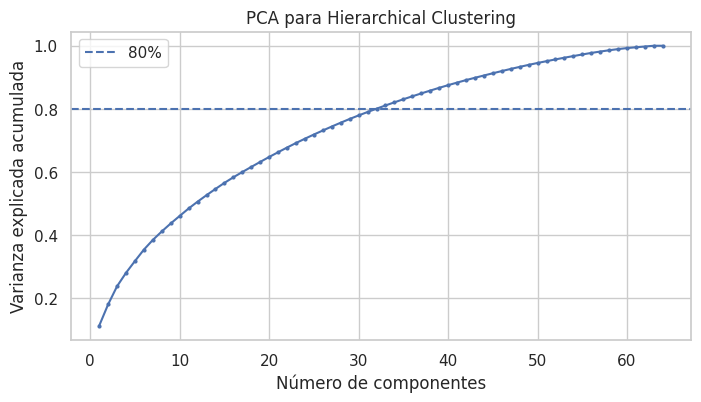

Número de componentes usados: 32


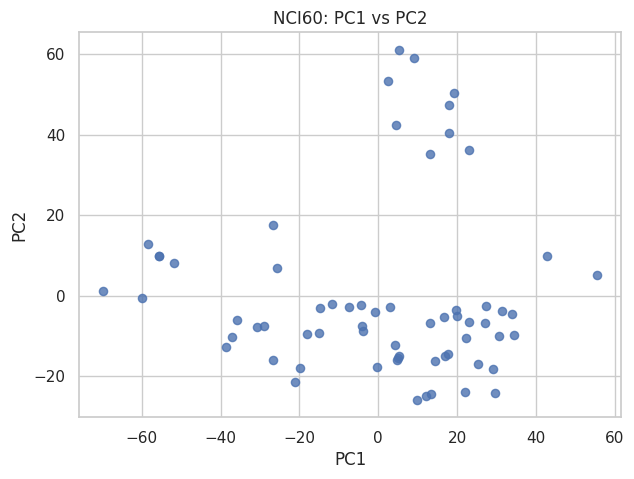

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(varianza_acumulada) + 1), varianza_acumulada, marker=".", markersize=4)
plt.axhline(0.80, linestyle="--", label="80%")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("PCA para Hierarchical Clustering")
plt.legend()
plt.show()

n_comp_h = max(2, int(np.argmax(varianza_acumulada >= 0.80) + 1))
pca_h = PCA(n_components=n_comp_h)
X_h = pca_h.fit_transform(X_nci_std)
print("Número de componentes usados:", n_comp_h)

plt.figure(figsize=(7, 5))
plt.scatter(X_h[:, 0], X_h[:, 1], s=35, alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("NCI60: PC1 vs PC2")
plt.show()

**Interpretación:** el gráfico muestra las muestras en dos dimensiones. La separación visual puede sugerir estructura, pero no determina por sí sola el número correcto de clusters; para ello también se examina el dendrograma.

## 14. Complete linkage con distancia euclidiana

Primero calculamos el clustering jerárquico con método `complete` y métrica `euclidean`, como pide el material. En este método, la distancia entre dos grupos se define por la mayor distancia entre una observación de un grupo y una del otro. El dendrograma muestra a qué altura se van fusionando los grupos.

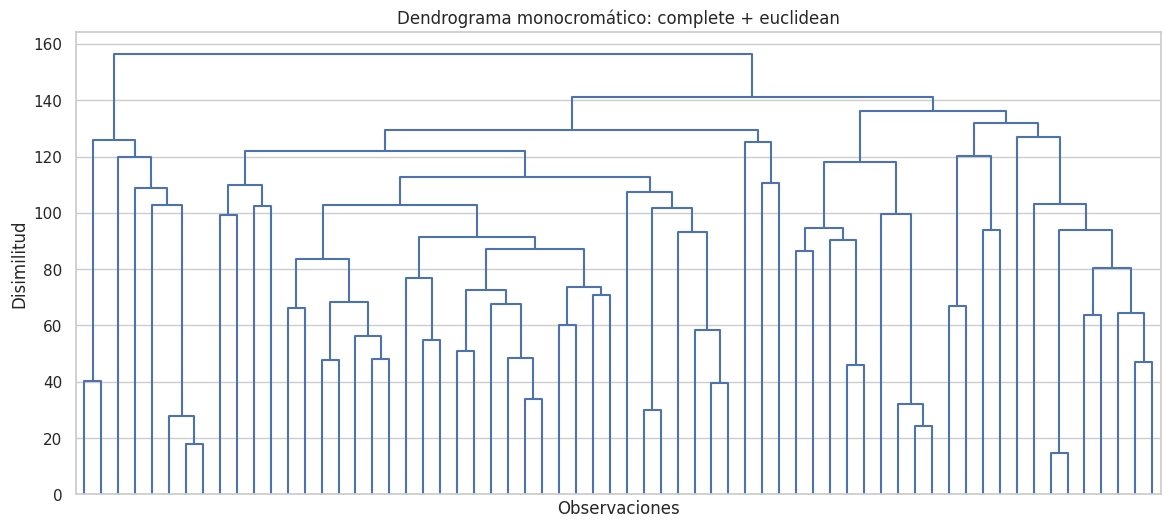

In [21]:
Z_complete_euclidean = linkage(X_h, method="complete", metric="euclidean")

plt.figure(figsize=(14, 6))
dendrogram(Z_complete_euclidean, no_labels=True, color_threshold=0)
plt.title("Dendrograma monocromático: complete + euclidean")
plt.xlabel("Observaciones")
plt.ylabel("Disimilitud")
plt.show()

**Interpretación:** cada hoja representa una muestra. Las fusiones a menor altura unen muestras o grupos más similares según la métrica usada. Saltos grandes en altura pueden ser una señal para considerar cortes antes de esas fusiones, aunque deben interpretarse junto con el objetivo del análisis.

## 15. Cambiar el umbral para obtener 2, 3 y 4 clusters

El umbral de corte determina cuántos grupos se forman. Se mostrarán dendrogramas con colores para cortes que producen 2, 3 y 4 clusters. **El umbral debe quedar entre dos alturas de fusión consecutivas**: usar exactamente la altura de una fusión puede incluir esa unión y producir un grupo menos del esperado. El código calcula un punto medio y verifica la cantidad de grupos obtenidos.

In [ ]:
def umbral_para_k(Z, k):
    """Calcula un umbral entre fusiones para obtener exactamente k grupos."""
    n = Z.shape[0] + 1
    if not 1 < k < n:
        raise ValueError("k debe estar entre 2 y n-1")

    # La fusión que deja k grupos está en la fila n-k-1.
    # Se elige el punto medio antes de la siguiente fusión.
    altura_inferior = float(Z[n-k-1, 2])
    altura_superior = float(Z[n-k, 2])
    umbral = (altura_inferior + altura_superior) / 2

    # Comprobación explícita del número de grupos que produce el corte.
    etiquetas_corte = fcluster(Z, t=umbral, criterion="distance")
    cantidad_obtenida = len(np.unique(etiquetas_corte))
    if cantidad_obtenida != k:
        raise RuntimeError(
            f"Se esperaban {k} clusters, pero el corte produjo {cantidad_obtenida}."
        )
    return umbral

fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for ax, k in zip(axes, [2, 3, 4]):
    umbral = umbral_para_k(Z_complete_euclidean, k)
    dendrogram(
        Z_complete_euclidean,
        no_labels=True,
        color_threshold=umbral,
        above_threshold_color="gray",
        ax=ax
    )
    ax.axhline(umbral, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Complete + euclidean: corte para {k} clusters (umbral={umbral:.3f})")
    ax.set_ylabel("Disimilitud")
    print(f"Corte solicitado: {k} clusters | grupos obtenidos: "
          f"{len(np.unique(fcluster(Z_complete_euclidean, t=umbral, criterion='distance')))}")
plt.tight_layout()
plt.show()

**Interpretación:** al cortar el árbol más abajo se obtienen más clusters; al cortar más arriba, menos. A diferencia de K-Means, el método jerárquico genera una estructura que permite observar distintas soluciones de agrupamiento en el mismo dendrograma.

## 16. Comparar euclidiana con correlación

Ahora repetimos el proceso con método `complete` y métrica `correlation`, como pide C3.4. La distancia euclidiana considera diferencias en los valores; la disimilitud basada en correlación se enfoca más en las diferencias de patrón entre perfiles. En SciPy, la métrica `correlation` es una distancia basada en la correlación.

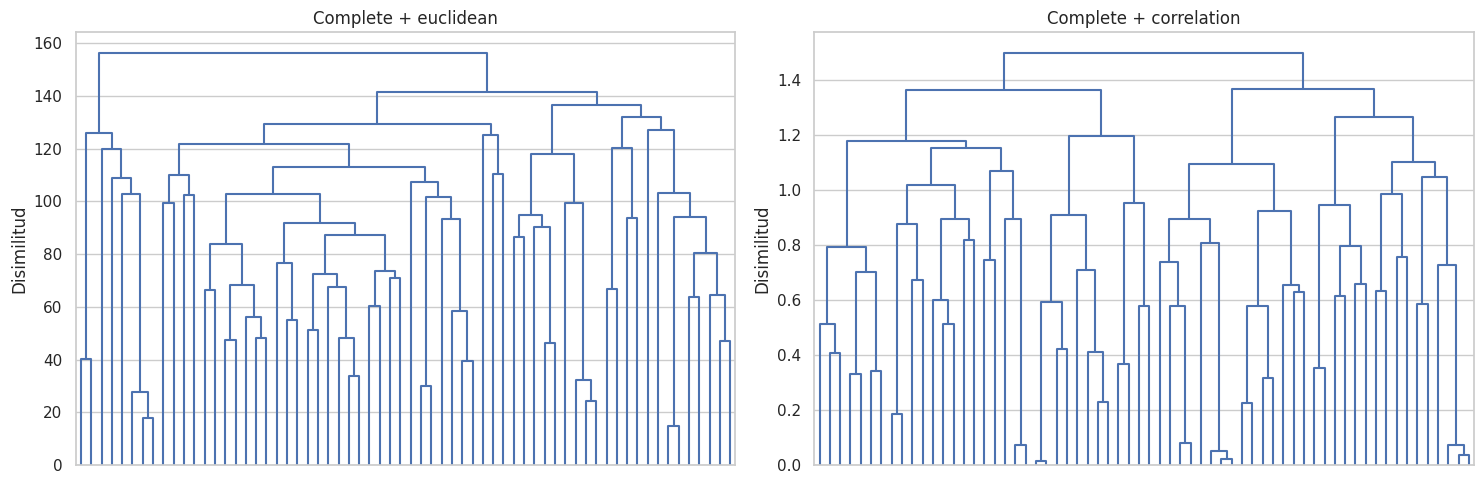

In [23]:
Z_complete_correlation = linkage(X_h, method="complete", metric="correlation")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z_complete_euclidean, no_labels=True, color_threshold=0, ax=axes[0])
axes[0].set_title("Complete + euclidean")
axes[0].set_ylabel("Disimilitud")

dendrogram(Z_complete_correlation, no_labels=True, color_threshold=0, ax=axes[1])
axes[1].set_title("Complete + correlation")
axes[1].set_ylabel("Disimilitud")
plt.tight_layout()
plt.show()

**Interpretación:** compara el orden y las alturas de las fusiones. Si el árbol cambia, significa que la definición de similitud altera qué muestras se agrupan primero. La distancia euclidiana enfatiza diferencias de magnitud, mientras que correlación enfatiza la semejanza de los patrones.

## 17. Comparar complete y average con distancia euclidiana

El material también pide repetir el proceso con método `average` y métrica `euclidean`. `average` utiliza el promedio de las distancias entre las observaciones de dos grupos; `complete` utiliza la distancia máxima. La comparación permite ver cómo la regla de enlace modifica el dendrograma.

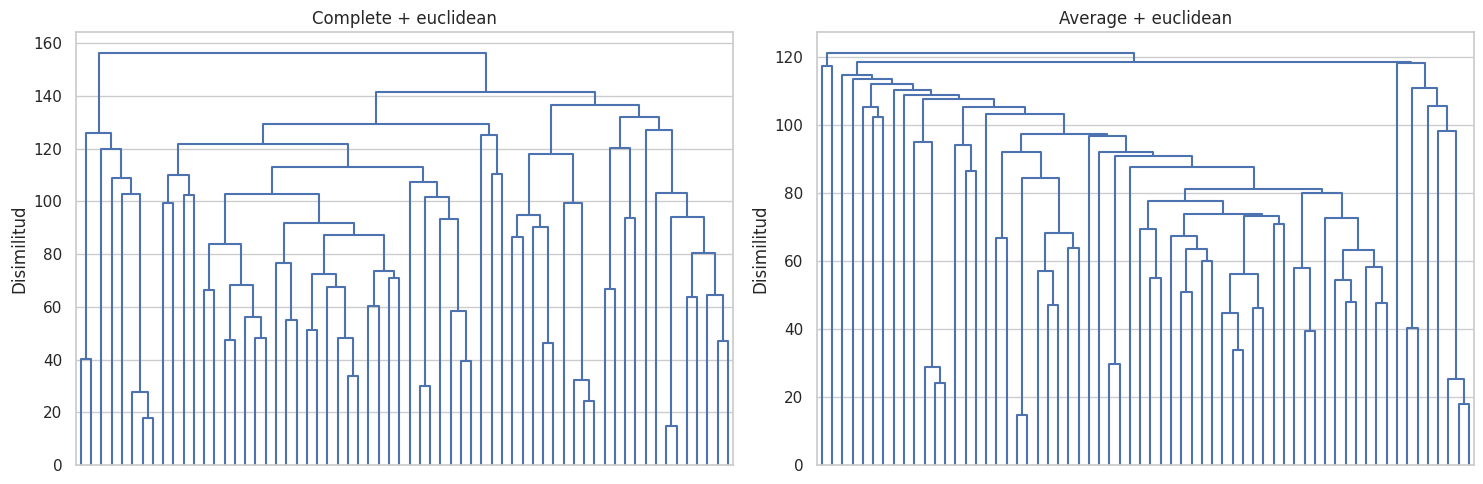

In [24]:
Z_average_euclidean = linkage(X_h, method="average", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z_complete_euclidean, no_labels=True, color_threshold=0, ax=axes[0])
axes[0].set_title("Complete + euclidean")
axes[0].set_ylabel("Disimilitud")

dendrogram(Z_average_euclidean, no_labels=True, color_threshold=0, ax=axes[1])
axes[1].set_title("Average + euclidean")
axes[1].set_ylabel("Disimilitud")
plt.tight_layout()
plt.show()

**Interpretación:** los dendrogramas pueden diferir porque `complete` se guía por la pareja más distante entre dos grupos, mientras que `average` usa el promedio de las distancias entre sus observaciones. Por ello, la estructura final depende tanto de la métrica como del método de enlace.

## 18. Obtener una asignación final de clusters y concluir

Para cerrar, se obtiene una solución de 3 clusters desde el dendrograma `complete + euclidean` y se compara con las clases conocidas mediante una tabla de contingencia. El número de tres grupos se utiliza aquí para facilitar la comparación y no implica que sea necesariamente el óptimo.

Cluster jerárquico,1,2,3
Clase real,,,
BREAST,0,3,4
CNS,0,5,0
COLON,0,2,5
K562A-repro,1,0,0
K562B-repro,1,0,0
LEUKEMIA,6,0,0
MCF7A-repro,0,0,1
MCF7D-repro,0,0,1
MELANOMA,0,1,7


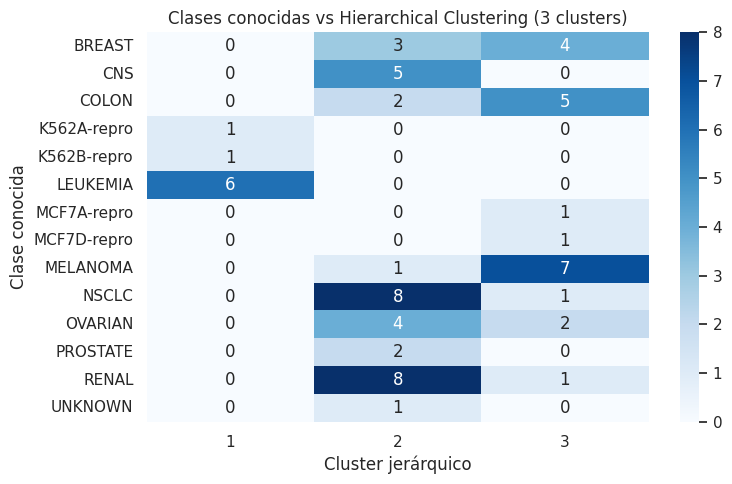

In [25]:
labels_h_3 = fcluster(Z_complete_euclidean, t=3, criterion="maxclust")
tabla_h = pd.crosstab(
    pd.Series(y_nci, name="Clase real"),
    pd.Series(labels_h_3, name="Cluster jerárquico")
)
display(tabla_h)

plt.figure(figsize=(8, 5))
sns.heatmap(tabla_h, annot=True, fmt="d", cmap="Blues")
plt.title("Clases conocidas vs Hierarchical Clustering (3 clusters)")
plt.xlabel("Cluster jerárquico")
plt.ylabel("Clase conocida")
plt.tight_layout()
plt.show()

## Conclusiones

### ¿Qué muestran los resultados?

- **K-Means con datos sintéticos:** la asignación inicial es aleatoria y los grupos se refinan al reasignar cada punto al centroide más cercano. En este conjunto, el resultado visual permite distinguir tres concentraciones de puntos. El algoritmo manual ilustra el procedimiento; `scikit-learn` lo repite con varias inicializaciones para reducir la dependencia de un único inicio.
- **Selección de clusters en NCI60:** en las variables estandarizadas, el mayor *silhouette* entre los valores probados corresponde a **k = 4** (aprox. 0.085). Con PCA y 32 componentes —que explican al menos el 80 % de la varianza— el mejor de los valores probados corresponde a **k = 5** (aprox. 0.132). Estos valores son relativamente bajos, por lo que la separación entre grupos no es fuerte. La elección es una referencia dentro del intervalo probado, no una prueba de que exista un número de grupos único y correcto.
- **PCA:** permite resumir las 6,830 variables originales y visualizar los datos en menos dimensiones. En este análisis se necesitan 32 componentes para alcanzar al menos el 80 % de la varianza. Las proyecciones PC1–PC2, PC1–PC3 y PC2–PC3 son útiles, pero no muestran toda la información conservada en los componentes.
- **Comparación con las clases conocidas:** las tablas de contingencia y el mapa de calor permiten observar qué clases se concentran en ciertos clusters y cuáles se distribuyen entre varios. Esto no significa que el algoritmo haya utilizado las clases: el clustering se ajustó sin esas etiquetas.
- **Heatmap de genes:** los 50 genes seleccionados son aquellos con mayor diferencia absoluta entre las expresiones promedio de los dos clusters comparados. El gráfico permite observar patrones relativos, pero no demuestra causalidad ni significancia estadística.
- **Hierarchical Clustering:** el dendrograma representa las fusiones sucesivas de las muestras. Los cortes a distintas alturas producen distintas cantidades de grupos; en este tutorial, los umbrales para 2, 3 y 4 clusters se calculan entre alturas de fusión consecutivas y se comprueban mediante el número de grupos resultante.
- **Métrica y enlace:** `euclidean` enfatiza diferencias de magnitud, mientras que `correlation` compara patrones. `complete` utiliza la mayor distancia entre dos grupos y `average` utiliza el promedio. Por ello, cambiar la métrica o el método de enlace puede cambiar la estructura del dendrograma.

### Conclusión general

K-Means y Hierarchical Clustering son métodos no supervisados, pero organizan los datos de manera distinta. K-Means requiere definir previamente el número de grupos y actualiza centroides; el método jerárquico construye un árbol que permite explorar diferentes cortes. En NCI60, las métricas y las gráficas deben interpretarse en conjunto: los resultados sugieren estructura en los datos, pero la separación moderada y la correspondencia parcial con las clases conocidas impiden afirmar que los clusters reproduzcan perfectamente las categorías biológicas.

## Referencias bibliográficas

1. Martínez Torteya, A. (s. f.). *C3.3 K-Means Clustering* [Presentación de clase]. Universidad de Monterrey.

2. Martínez Torteya, A. (s. f.). *C3.4 Hierarchical Clustering* [Presentación de clase]. Universidad de Monterrey.

3. James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0


4. OpenAI. (2026). *ChatGPT* (GPT-6) [Modelo de lenguaje de inteligencia artificial]. https://chatgpt.com/

## Exportar el tutorial

Para generar una versión HTML con las salidas y gráficas, ejecuta en una terminal desde la carpeta donde guardaste este cuaderno:

```bash
jupyter nbconvert --to html --execute "A3_2_Clustering_Tutorial_Corregido.ipynb"
```

Para exportar a PDF, puedes usar la opción **Archivo → Imprimir** del navegador después de abrir el HTML, o ejecutar `jupyter nbconvert --to webpdf --execute "A3_2_Clustering_Tutorial_Corregido.ipynb"` si tienes instalado el soporte de `webpdf`.